# 12 — Hasil Eksperimen Revisi (multi-seed)

Notebook ini **hanya membaca** hasil eksperimen revisi reviewer; tidak ada
training di sini. Training dijalankan lewat CLI karena butuh berjam-jam dan
harus bisa dilanjutkan bila terputus.

**Konfigurasi utama = `bn_frozen`** sejak brief lanjutan 2026-11-13: backbone
beku total (bobot **dan** statistik BatchNorm), hanya head `Linear(5)` yang
dilatih. Di laporan `bn_frozen` disebut **main**, dan konfigurasi `main` lama
(BN beradaptasi) disebut **bn_adapt**. Ubah `MAIN_CONFIG = 'main'` di sel Setup
untuk melihat hasil lama (figur lama di `results/figures/paper_revision/`).

```bash
# konfigurasi utama baru (5 seed) + ablasi di atas bn_frozen (3 seed) + diagnostik 60 epoch
python -m scripts.run_revision --configs bn_frozen bnf_focal bnf_sampler bnf_aug_all_x3 bnf_aug_all_balanced bnf_e60
python -m scripts.aggregate_revision --main-config bn_frozen            # -> runs/summary/bnfrozen/
python -m scripts.revision_extras timing  --main-config bn_frozen       # GPU harus menganggur
python -m scripts.revision_extras support --main-config bn_frozen
python -m scripts.revision_figures --main-config bn_frozen              # -> results/figures/paper_revision_bnfrozen/
```

Seed: konfigurasi utama `(42, 0, 1, 2, 3)`, ablasi `(42, 0, 1)` — didefinisikan di
`scripts/run_revision.py` (`MAIN_SEEDS`, `ABLATION_SEEDS`, `CONFIGS`). Seed hanya
mengubah inisialisasi head dan urutan shuffle; dataset, split, dan augmentasi di
disk sama untuk semua seed. **Seluruh pemilihan (konfigurasi utama, checkpoint,
varian TTA, ambang) dilakukan di valid**; test hanya untuk pelaporan.

| Bagian | Isi | Sumber |
| --- | --- | --- |
| 1 | Status run | `runs/*/metrics.json` |
| 2 | Regenerasi (opsional) | CLI |
| 3 | Pemilihan TTA di valid | `tables.md` |
| 4 | Tabel utama test ± std, validasi, per seed | `per_run.csv` |
| 5 | F1 per kelas, pola kesalahan, peringkat | `per_run.csv`, `tables.md` |
| 6 | Ablasi + efek BN (R1.6, R1.7) | `tables.md` |
| 7 | Efek TTA & ambang P(good) | `tables.md` |
| 8 | Diagnostik 60 epoch | `tables.md`, history |
| 9 | Statistik per foto (proporsi `good`) | `runs/summary/photo_stats.csv` |
| 10 | Waktu per sampel 50 g & efisiensi | `timing.md`, `support.md` |
| 11 | Epoch checkpoint semua konfigurasi | `tables.md` |
| 12 | Pratinjau figur | `results/figures/paper_revision_bnfrozen/` |

Laporan naratif: `docs/paper_handoff_2026-11-13_bnfrozen.md` (dan
`REVISION_RESULTS.md` untuk revisi 2026-11-12).

## Setup

In [1]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: C:\Users\DZXP\Documents\ta-green-bean


In [2]:
import json
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from configs.base_config import CLASS_NAMES, FIGURES_DIR
from scripts.run_revision import CONFIGS, RUNS_DIR
from src.analysis.paper_style import MODEL_COLORS, paper_style

# scripts.run_revision (entry point CLI) memaksa backend Agg saat diimpor;
# kembalikan backend inline agar plt.show() di notebook tidak kosong.
%matplotlib inline

#: 'bn_frozen' = konfigurasi utama sejak 2026-11-13; 'main' = konfigurasi utama lama (bn_adapt).
MAIN_CONFIG = 'bn_frozen'

PROFILES = {
    'bn_frozen': {'summary': RUNS_DIR / 'summary' / 'bnfrozen', 'agg': 'aggregate_bnfrozen',
                  'support': 'support_bnfrozen', 'timing': 'timing_bnfrozen',
                  'figures': FIGURES_DIR / 'paper_revision_bnfrozen',
                  'ablation': ['bnf_focal', 'bnf_sampler', 'bnf_aug_all_x3', 'bnf_aug_all_balanced'],
                  'compare': 'main'},
    'main': {'summary': RUNS_DIR / 'summary', 'agg': 'aggregate', 'support': 'support', 'timing': 'timing',
             'figures': FIGURES_DIR / 'paper_revision',
             'ablation': ['focal_loss', 'weighted_sampler', 'aug_all_x3', 'aug_all_balanced'],
             'compare': 'bn_frozen'},
}
P = PROFILES[MAIN_CONFIG]
MODELS = ['resnet50', 'mobilenetv3', 'inceptionv3']
MODEL_LABELS = {'resnet50': 'ResNet-50', 'mobilenetv3': 'MobileNetV3-L', 'inceptionv3': 'InceptionV3'}
CONFIG_ORDER = ['bn_frozen', 'bnf_focal', 'bnf_sampler', 'bnf_aug_all_x3', 'bnf_aug_all_balanced', 'bnf_e60',
                'main', 'focal_loss', 'weighted_sampler', 'aug_all_x3', 'aug_all_balanced', 'repro_valacc']

SUMMARY_DIR = P['summary']
RESULTS_JSON = PROJECT_ROOT / 'revision_results.json'
FIG_DIR = P['figures']

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
print('Konfigurasi utama:', MAIN_CONFIG, '| ringkasan:', SUMMARY_DIR.relative_to(PROJECT_ROOT))

Konfigurasi utama: bn_frozen | ringkasan: runs\summary\bnfrozen


## 1. Status run

Jumlah run selesai (`metrics.json` ada) dibanding yang direncanakan di `CONFIGS`.
Run ablasi lama (BN beradaptasi) tetap disimpan sebagai arsip.

In [3]:
rows = []
for cfg in CONFIG_ORDER:
    for model in MODELS:
        seeds = CONFIGS[cfg]['seeds']
        done = [s for s in seeds if (RUNS_DIR / f'{model}_{cfg}_seed{s}' / 'metrics.json').exists()]
        rows.append({'config': cfg, 'model': model, 'bn_mode': CONFIGS[cfg]['bn_mode'],
                     'epochs': CONFIGS[cfg].get('epochs', 30), 'rencana': len(seeds), 'selesai': len(done),
                     'belum': [s for s in seeds if s not in done]})
status = pd.DataFrame(rows)
print(f"Total: {status['selesai'].sum()} / {status['rencana'].sum()} run selesai")
status

Total: 108 / 108 run selesai


,config,model,bn_mode,epochs,rencana,selesai,belum
0,bn_frozen,resnet50,frozen,30,5,5,[]
1,bn_frozen,mobilenetv3,frozen,30,5,5,[]
2,bn_frozen,inceptionv3,frozen,30,5,5,[]
3,bnf_focal,resnet50,frozen,30,3,3,[]
4,bnf_focal,mobilenetv3,frozen,30,3,3,[]
5,bnf_focal,inceptionv3,frozen,30,3,3,[]
6,bnf_sampler,resnet50,frozen,30,3,3,[]
7,bnf_sampler,mobilenetv3,frozen,30,3,3,[]
8,bnf_sampler,inceptionv3,frozen,30,3,3,[]
9,bnf_aug_all_x3,resnet50,frozen,30,3,3,[]


## 2. (Opsional) Regenerasi artefak

Biarkan `REGENERATE = False` untuk sekadar membaca hasil. Ubah ke `True` untuk
menjalankan ulang agregasi, analisis pendukung, dan figur (tidak melatih ulang).
`timing` dan `support` mengukur latensi GPU — jalankan hanya saat GPU tidak dipakai
proses lain.

In [4]:
REGENERATE = False

STEPS = [
    ['scripts.aggregate_revision', '--main-config', MAIN_CONFIG],
    ['scripts.revision_extras', 'timing', '--main-config', MAIN_CONFIG],
    ['scripts.revision_extras', 'support', '--main-config', MAIN_CONFIG],
    ['scripts.revision_figures', '--main-config', MAIN_CONFIG],
]
if REGENERATE:
    for step in STEPS:
        print('>>', ' '.join(step))
        subprocess.run([sys.executable, '-m', *step], cwd=PROJECT_ROOT, check=True)

In [5]:
per_run = pd.read_csv(SUMMARY_DIR / 'per_run.csv')
results = json.loads(RESULTS_JSON.read_text(encoding='utf-8'))
agg = results[P['agg']]
SEL_TTA = agg['tta_selection']['uniform_choice']
TABLES_MD = (SUMMARY_DIR / 'tables.md').read_text(encoding='utf-8')


def mean_std(series: pd.Series, digits: int = 3, scale: float = 1.0) -> str:
    # Rata-rata ± simpangan baku sampel (ddof=1), seperti di aggregate_revision.
    v = series.to_numpy(dtype=float) * scale
    sd = v.std(ddof=1) if len(v) > 1 else 0.0
    return f'{v.mean():.{digits}f} ± {sd:.{digits}f}'


def summary_table(df: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    # Tabel mean ± std untuk metrik inti, dikelompokkan menurut `by`.
    return df.groupby(by, sort=False).apply(lambda g: pd.Series({
        'n': len(g),
        'Acc': mean_std(g['accuracy']),
        'Macro P': mean_std(g['precision']),
        'Macro R': mean_std(g['recall']),
        'Macro F1': mean_std(g['f1']),
        'Defect recall': mean_std(g['defect_recall']),
        'Miss rate (%)': mean_std(g['defect_miss_rate'], 1, 100),
        'insect→good': mean_std(g['insect_to_good'], 1),
    }), include_groups=False)


def show_section(prefix: str) -> None:
    # Tampilkan satu bagian '### ...' dari tables.md profil aktif.
    for block in TABLES_MD.split('### ')[1:]:
        if block.startswith(prefix):
            display(Markdown('### ' + block))
            return
    print(f'Bagian "{prefix}" tidak ditemukan di tables.md')


def sel(**kw) -> pd.DataFrame:
    mask = np.ones(len(per_run), dtype=bool)
    for key, value in kw.items():
        mask &= per_run[key].isin(value if isinstance(value, (list, tuple)) else [value]).to_numpy()
    return per_run[mask]


print(f"{agg['n_runs']} run teragregasi; {len(per_run)} baris (run x split x TTA); TTA terpilih di valid: {SEL_TTA}")

108 run teragregasi; 864 baris (run x split x TTA); TTA terpilih di valid: d4


## 3. Pemilihan varian TTA di VALID (R1.9)

Rata-rata **val F1 makro** lintas 5 seed konfigurasi utama; satu varian yang sama
dipakai untuk ketiga arsitektur (rata-rata 3 model tertinggi). Varian terpilih
dipakai untuk semua tabel dan figur berikutnya.

In [6]:
show_section('Pemilihan TTA')

### Pemilihan TTA di VALID (F1 makro, bn_frozen)

| Varian TTA | ResNet-50 | MobileNetV3-L | InceptionV3 | Rata-rata 3 model |
|---|--:|--:|--:|--:|
| tanpa | 0.781 ± 0.001 | 0.784 ± 0.003 | 0.748 ± 0.006 | 0.771 |
| flip H | 0.776 ± 0.004 | 0.785 ± 0.007 | 0.736 ± 0.013 | 0.766 |
| flip H+V | 0.788 ± 0.009 | 0.772 ± 0.007 | 0.758 ± 0.012 | 0.773 |
| D4 | 0.795 ± 0.011 **(terbaik)** | 0.793 ± 0.007 **(terbaik)** | 0.774 ± 0.013 **(terbaik)** | 0.787 **(terpilih)** |



## 4. Tabel utama — test (n = 863), 5 seed

Checkpoint = epoch dengan **val F1 makro** tertinggi (valid tanpa TTA, seri →
epoch lebih awal). Miss rate dihitung eksak dari hitungan (cacat diprediksi
`good` / 428 cacat), dibulatkan sekali.

In [7]:
for tta, label in [(SEL_TTA, f'TTA {SEL_TTA}'), ('none', 'tanpa TTA')]:
    display(Markdown(f'**Test, {label}**'))
    t = summary_table(sel(config=MAIN_CONFIG, split='test', tta=tta), ['model'])
    display(t.loc[MODELS].rename(index=MODEL_LABELS))

**Test, TTA d4**

,n,Acc,Macro P,Macro R,Macro F1,Defect recall,Miss rate (%),insect→good
model,,,,,,,,
ResNet-50,5,0.823 ± 0.006,0.784 ± 0.007,0.788 ± 0.006,0.781 ± 0.004,0.932 ± 0.011,6.8 ± 1.1,15.4 ± 3.2
MobileNetV3-L,5,0.796 ± 0.008,0.753 ± 0.006,0.762 ± 0.008,0.753 ± 0.005,0.936 ± 0.011,6.4 ± 1.1,12.8 ± 3.1
InceptionV3,5,0.796 ± 0.002,0.736 ± 0.005,0.747 ± 0.008,0.739 ± 0.005,0.907 ± 0.013,9.3 ± 1.3,20.8 ± 1.9


**Test, tanpa TTA**

,n,Acc,Macro P,Macro R,Macro F1,Defect recall,Miss rate (%),insect→good
model,,,,,,,,
ResNet-50,5,0.809 ± 0.004,0.769 ± 0.008,0.730 ± 0.005,0.747 ± 0.005,0.847 ± 0.012,15.3 ± 1.2,28.8 ± 1.8
MobileNetV3-L,5,0.807 ± 0.005,0.763 ± 0.004,0.734 ± 0.011,0.746 ± 0.008,0.874 ± 0.014,12.6 ± 1.4,24.0 ± 3.1
InceptionV3,5,0.789 ± 0.006,0.727 ± 0.008,0.705 ± 0.007,0.712 ± 0.007,0.865 ± 0.010,13.5 ± 1.0,26.4 ± 2.4


In [8]:
show_section('Validasi')

### Validasi (mean ± std)

| Model | Val acc tanpa TTA | Val F1 tanpa TTA | Val acc D4 | Val F1 D4 |
|---|--:|--:|--:|--:|
| ResNet-50 | 0.824 ± 0.001 | 0.781 ± 0.001 | 0.820 ± 0.013 | 0.795 ± 0.011 |
| MobileNetV3-L | 0.828 ± 0.001 | 0.784 ± 0.003 | 0.823 ± 0.009 | 0.793 ± 0.007 |
| InceptionV3 | 0.808 ± 0.003 | 0.748 ± 0.006 | 0.814 ± 0.012 | 0.774 ± 0.013 |



Nilai per seed (F1 makro test) dan epoch checkpoint terpilih:

In [9]:
main_test = sel(config=MAIN_CONFIG, split='test')
f1_seed = main_test.pivot_table(index='seed', columns=['tta', 'model'], values='f1')[
    [('none', m) for m in MODELS] + [(SEL_TTA, m) for m in MODELS]]
epoch_seed = sel(config=MAIN_CONFIG, split='test', tta=SEL_TTA).pivot(index='seed', columns='model',
                                                                       values='best_epoch')[MODELS]
display(f1_seed.round(4))
display(epoch_seed.rename(columns=MODEL_LABELS))

tta       none                               d4                        
model resnet50 mobilenetv3 inceptionv3 resnet50 mobilenetv3 inceptionv3
seed                                                                   
0       0.7491      0.7579      0.7198   0.7793      0.7556      0.7478
1       0.7410      0.7450      0.7053   0.7755      0.7557      0.7380
2       0.7524      0.7366      0.7035   0.7834      0.7567      0.7379
3       0.7424      0.7434      0.7166   0.7851      0.7473      0.7358
42      0.7480      0.7485      0.7152   0.7839      0.7472      0.7357

model,ResNet-50,MobileNetV3-L,InceptionV3
seed,,,
0,22,13,27
1,27,21,22
2,15,28,20
3,27,30,13
42,29,12,24


In [10]:
show_section('Nilai per seed, test TTA')

### Nilai per seed, test TTA D4

| Model | Seed | Epoch | Acc | Macro P | Macro R | Macro F1 | Defect recall | Miss rate | I→G |
|---|--:|--:|--:|--:|--:|--:|--:|--:|--:|
| ResNet-50 | 42 | 29 | 0.825 | 0.784 | 0.791 | 0.784 | 0.937 | 6.3% | 14 |
| ResNet-50 | 0 | 22 | 0.816 | 0.773 | 0.793 | 0.779 | 0.946 | 5.4% | 11 |
| ResNet-50 | 1 | 27 | 0.819 | 0.785 | 0.780 | 0.775 | 0.928 | 7.2% | 18 |
| ResNet-50 | 2 | 15 | 0.831 | 0.788 | 0.783 | 0.783 | 0.916 | 8.4% | 19 |
| ResNet-50 | 3 | 27 | 0.825 | 0.790 | 0.791 | 0.785 | 0.935 | 6.5% | 15 |
| MobileNetV3-L | 42 | 12 | 0.788 | 0.752 | 0.756 | 0.747 | 0.939 | 6.1% | 13 |
| MobileNetV3-L | 0 | 13 | 0.793 | 0.747 | 0.773 | 0.756 | 0.953 | 4.7% | 8 |
| MobileNetV3-L | 1 | 21 | 0.802 | 0.754 | 0.766 | 0.756 | 0.930 | 7.0% | 15 |
| MobileNetV3-L | 2 | 28 | 0.806 | 0.762 | 0.758 | 0.757 | 0.925 | 7.5% | 16 |
| MobileNetV3-L | 3 | 30 | 0.791 | 0.749 | 0.755 | 0.747 | 0.932 | 6.8% | 12 |
| InceptionV3 | 42 | 24 | 0.796 | 0.737 | 0.736 | 0.736 | 0.886 | 11.4% | 23 |
| InceptionV3 | 0 | 27 | 0.798 | 0.742 | 0.758 | 0.748 | 0.918 | 8.2% | 20 |
| InceptionV3 | 1 | 22 | 0.794 | 0.729 | 0.750 | 0.738 | 0.918 | 8.2% | 18 |
| InceptionV3 | 2 | 20 | 0.795 | 0.735 | 0.748 | 0.738 | 0.907 | 9.3% | 22 |
| InceptionV3 | 3 | 13 | 0.795 | 0.736 | 0.743 | 0.736 | 0.907 | 9.3% | 21 |



## 5. F1 per kelas, pola kesalahan, dan peringkat arsitektur

In [11]:
for tta in [SEL_TTA, 'none']:
    sub = sel(config=MAIN_CONFIG, split='test', tta=tta)
    t = pd.DataFrame({MODEL_LABELS[m]: {c: mean_std(sub[sub.model == m][f'f1_{c}']) for c in CLASS_NAMES}
                      for m in MODELS})
    display(Markdown(f'**F1 per kelas, TTA {tta}**'))
    display(t)

**F1 per kelas, TTA d4**

,ResNet-50,MobileNetV3-L,InceptionV3
good,0.904 ± 0.007,0.888 ± 0.009,0.890 ± 0.003
black,0.729 ± 0.008,0.691 ± 0.009,0.733 ± 0.003
chipped,0.696 ± 0.007,0.687 ± 0.008,0.673 ± 0.010
dry_pods,0.889 ± 0.013,0.860 ± 0.013,0.802 ± 0.009
insect_damage,0.688 ± 0.008,0.637 ± 0.008,0.597 ± 0.017


**F1 per kelas, TTA none**

,ResNet-50,MobileNetV3-L,InceptionV3
good,0.899 ± 0.002,0.905 ± 0.003,0.900 ± 0.002
black,0.735 ± 0.004,0.692 ± 0.011,0.720 ± 0.019
chipped,0.650 ± 0.008,0.678 ± 0.016,0.603 ± 0.022
dry_pods,0.861 ± 0.010,0.828 ± 0.014,0.767 ± 0.007
insect_damage,0.588 ± 0.005,0.629 ± 0.013,0.571 ± 0.015


In [12]:
show_section('Pola kesalahan')
show_section('Peringkat arsitektur')

### Pola kesalahan terbanyak (test, TTA D4)

| Model | Peringkat | Pasangan (true→pred) | Seed 42 | Rata-rata seed (± std) |
|---|--:|---|--:|--:|
| ResNet-50 | 1 | good→black (G→B) | 28 | 26.8 ± 4.4 |
| ResNet-50 | 2 | insect_damage→good (I→G) | 14 | 15.4 ± 3.2 |
| ResNet-50 | 3 | chipped→black (C→B) | 15 | 14.8 ± 0.4 |
| ResNet-50 | 4 | good→insect_damage (G→I) | 14 | 14.2 ± 4.1 |
| MobileNetV3-L | 1 | good→black (G→B) | 45 | 36.8 ± 5.4 |
| MobileNetV3-L | 2 | good→insect_damage (G→I) | 21 | 22.6 ± 5.7 |
| MobileNetV3-L | 3 | insect_damage→black (I→B) | 20 | 17.8 ± 1.5 |
| MobileNetV3-L | 4 | insect_damage→good (I→G) | 13 | 12.8 ± 3.1 |
| InceptionV3 | 1 | good→black (G→B) | 16 | 23.0 ± 5.6 |
| InceptionV3 | 2 | insect_damage→good (I→G) | 23 | 20.8 ± 1.9 |
| InceptionV3 | 3 | good→insect_damage (G→I) | 19 | 19.8 ± 2.2 |
| InceptionV3 | 4 | insect_damage→chipped (I→C) | 13 | 14.2 ± 2.9 |



### Peringkat arsitektur vs variasi antar-seed

**F1 makro** (test, TTA D4)

| Selisih | Rata-rata (paired) | Std selisih | Seed dengan selisih > 0 |
|---|--:|--:|--:|
| resnet50-mobilenetv3 | +0.029 | 0.008 | 5/5 |
| mobilenetv3-inceptionv3 | +0.013 | 0.005 | 5/5 |
| resnet50-inceptionv3 | +0.042 | 0.008 | 5/5 |

Urutan F1 ResNet-50 > MobileNetV3-L > InceptionV3 bertahan di 5/5 seed. Std antar-seed per model: ResNet-50 0.004, MobileNetV3-L 0.005, InceptionV3 0.005.

**Miss rate (poin %)** (test, TTA D4)

| Selisih | Rata-rata (paired) | Std selisih | Seed dengan selisih > 0 |
|---|--:|--:|--:|
| resnet50-mobilenetv3 | +0.4 | 0.5 | 4/5 |
| mobilenetv3-inceptionv3 | -2.9 | 1.6 | 0/5 |
| resnet50-inceptionv3 | -2.5 | 1.7 | 0/5 |

Urutan miss rate (terendah → tertinggi) per seed: 42: M < R < I; 0: M < R < I; 1: M < R < I; 2: M < R < I; 3: R < M < I (2 urutan berbeda). Std antar-seed per model (poin %): ResNet-50 1.1, MobileNetV3-L 1.1, InceptionV3 1.3. Selisih > 0 berarti model pertama lebih banyak meloloskan cacat.



## 6. Ablasi (R1.6, R1.7)

Setiap baris ablasi hanya mengubah **satu** faktor dari konfigurasi utama.
Ablasi memakai 3 seed `(42, 0, 1)`, jadi baris `main [seed 42,0,1]` disertakan
agar perbandingan berpasangan. Pemilihan memakai **val F1**; kolom test hanya
dilaporkan.

In [13]:
show_section('Ablasi (test')
show_section('Ablasi (val')

### Ablasi (test, F1 makro & miss rate, TTA D4)

| Konfigurasi | Seed | ResNet-50 F1 | ResNet-50 miss | MobileNetV3-L F1 | MobileNetV3-L miss | InceptionV3 F1 | InceptionV3 miss | Val F1 rata2 |
|---|---|--:|--:|--:|--:|--:|--:|--:|
| main (bn_frozen, class weights, TTA D4) | 5 | 0.781 ± 0.004 | 6.8 ± 1.1% | 0.753 ± 0.005 | 6.4 ± 1.1% | 0.739 ± 0.005 | 9.3 ± 1.3% | 0.787 |
| main [seed 42,0,1] | 3 | 0.780 ± 0.004 | 6.3 ± 0.9% | 0.753 ± 0.005 | 5.9 ± 1.2% | 0.741 ± 0.006 | 9.3 ± 1.9% | 0.785 |
| main tanpa TTA | 5 | 0.747 ± 0.005 | 15.3 ± 1.2% | 0.746 ± 0.008 | 12.6 ± 1.4% | 0.712 ± 0.007 | 13.5 ± 1.0% | 0.771 |
| bn_adapt (BN train mode; main lama) | 5 | 0.780 ± 0.011 | 11.4 ± 2.1% | 0.752 ± 0.002 | 10.7 ± 1.0% | 0.734 ± 0.011 | 9.2 ± 2.5% | 0.744 |
| focal loss (γ=2, α=bobot kelas) | 3 | 0.779 ± 0.002 | 7.3 ± 1.3% | 0.746 ± 0.007 | 6.1 ± 1.2% | 0.735 ± 0.009 | 8.6 ± 1.2% | 0.782 |
| weighted sampler | 3 | 0.784 ± 0.003 | 7.2 ± 2.0% | 0.758 ± 0.010 | 7.6 ± 1.1% | 0.739 ± 0.004 | 9.1 ± 1.9% | 0.787 |
| aug_all_x3 (good ×3) | 3 | 0.784 ± 0.004 | 10.5 ± 2.0% | 0.762 ± 0.003 | 10.0 ± 0.9% | 0.741 ± 0.013 | 12.2 ± 1.1% | 0.801 |
| aug_all_balanced (good diganti varian) | 3 | 0.780 ± 0.007 | 10.0 ± 1.5% | 0.756 ± 0.003 | 9.9 ± 1.6% | 0.742 ± 0.005 | 13.7 ± 1.0% | 0.803 |



### Ablasi (val F1 makro, baris yang sama)

| Konfigurasi | Seed | ResNet-50 val F1 | MobileNetV3-L val F1 | InceptionV3 val F1 | Rata-rata 3 model | Δ vs main (seed sama) |
|---|---|--:|--:|--:|--:|--:|
| main (bn_frozen, class weights, TTA D4) | 5 | 0.795 ± 0.011 | 0.793 ± 0.007 | 0.774 ± 0.013 | 0.787 | — |
| main [seed 42,0,1] | 3 | 0.789 ± 0.009 | 0.791 ± 0.009 | 0.776 ± 0.016 | 0.785 | — |
| main tanpa TTA | 5 | 0.781 ± 0.001 | 0.784 ± 0.003 | 0.748 ± 0.006 | 0.771 | — |
| bn_adapt (BN train mode; main lama) | 5 | 0.782 ± 0.004 | 0.755 ± 0.003 | 0.694 ± 0.004 | 0.744 | -0.043 |
| focal loss (γ=2, α=bobot kelas) | 3 | 0.795 ± 0.008 | 0.790 ± 0.005 | 0.760 ± 0.023 | 0.782 | -0.003 |
| weighted sampler | 3 | 0.798 ± 0.006 | 0.795 ± 0.005 | 0.767 ± 0.005 | 0.787 | +0.002 |
| aug_all_x3 (good ×3) | 3 | 0.814 ± 0.006 | 0.815 ± 0.007 | 0.775 ± 0.011 | 0.801 | +0.016 |
| aug_all_balanced (good diganti varian) | 3 | 0.810 ± 0.007 | 0.813 ± 0.006 | 0.786 ± 0.013 | 0.803 | +0.018 |



In [14]:
show_section('bn_frozen vs')

### bn_frozen vs bn_adapt (berpasangan, TTA D4)

| Model | Seed | Val F1 bn_adapt → bn_frozen | Test F1 bn_adapt → bn_frozen | Test acc bn_adapt → bn_frozen | Test miss bn_adapt → bn_frozen | Δ val F1 (paired) | Seed val F1 lebih tinggi |
|---|--:|---|---|---|---|--:|--:|
| ResNet-50 | 5 | 0.782 ± 0.004 → 0.795 ± 0.011 | 0.780 ± 0.011 → 0.781 ± 0.004 | 0.827 ± 0.006 → 0.823 ± 0.006 | 11.4 ± 2.1% → 6.8 ± 1.1% | +0.012 ± 0.015 | 4/5 |
| MobileNetV3-L | 5 | 0.755 ± 0.003 → 0.793 ± 0.007 | 0.752 ± 0.002 → 0.753 ± 0.005 | 0.808 ± 0.002 → 0.796 ± 0.008 | 10.7 ± 1.0% → 6.4 ± 1.1% | +0.038 ± 0.003 | 5/5 |
| InceptionV3 | 5 | 0.694 ± 0.004 → 0.774 ± 0.013 | 0.734 ± 0.011 → 0.739 ± 0.005 | 0.789 ± 0.008 → 0.796 ± 0.002 | 9.2 ± 2.5% → 9.3 ± 1.3% | +0.080 ± 0.011 | 5/5 |



## 7. Efek TTA di test & ambang P(good)

In [15]:
show_section('Efek TTA')
show_section('Ambang P(good)')

### Efek TTA di test (tanpa → D4)

| Model | F1 tanpa → TTA | Acc tanpa → TTA | Miss tanpa → TTA | I→G tanpa → TTA | Run F1 naik | Run miss turun |
|---|---|---|---|---|--:|--:|
| ResNet-50 | 0.747 ± 0.005 → 0.781 ± 0.004 | 0.809 ± 0.004 → 0.823 ± 0.006 | 15.3 ± 1.2% → 6.8 ± 1.1% | 28.8 ± 1.8 → 15.4 ± 3.2 | 5/5 | 5/5 |
| MobileNetV3-L | 0.746 ± 0.008 → 0.753 ± 0.005 | 0.807 ± 0.005 → 0.796 ± 0.008 | 12.6 ± 1.4% → 6.4 ± 1.1% | 24.0 ± 3.1 → 12.8 ± 3.1 | 3/5 | 5/5 |
| InceptionV3 | 0.712 ± 0.007 → 0.739 ± 0.005 | 0.789 ± 0.006 → 0.796 ± 0.002 | 13.5 ± 1.0% → 9.3 ± 1.3% | 26.4 ± 2.4 → 20.8 ± 1.9 | 5/5 | 5/5 |



### Ambang P(good), dipilih di VALID (TTA D4)

| Model | Ambang | Val miss argmax → ambang | Val F1 argmax → ambang | Test miss argmax → ambang | Test F1 argmax → ambang | Test acc argmax → ambang |
|---|--:|---|---|---|---|---|
| ResNet-50 | 0.45 | 5.3% → 5.2% | 0.795 → 0.788 | 6.8 ± 1.1% → 6.1 ± 1.0% | 0.781 ± 0.004 → 0.780 ± 0.005 | 0.823 ± 0.006 → 0.820 ± 0.007 |
| MobileNetV3-L | 0.45 | 5.1% → 4.5% | 0.793 → 0.784 | 6.4 ± 1.1% → 5.7 ± 1.0% | 0.753 ± 0.005 → 0.750 ± 0.005 | 0.796 ± 0.008 → 0.792 ± 0.010 |
| InceptionV3 | 0.45 | 8.8% → 7.8% | 0.774 → 0.767 | 9.3 ± 1.3% → 8.0 ± 1.4% | 0.739 ± 0.005 → 0.738 ± 0.006 | 0.796 ± 0.002 → 0.793 ± 0.004 |



## 8. Diagnostik jumlah epoch (60 epoch, seed 42) — hanya dilaporkan

Checkpoint `bn_frozen` jatuh di epoch akhir. Run `bnf_e60` melatih seed 42 selama
60 epoch (hyperparameter lain sama). 30 epoch pertama harus identik dengan run
30 epoch. Konfigurasi utama **tidak** diubah berdasarkan diagnostik ini.

In [16]:
show_section('Diagnostik 60 epoch')

### Diagnostik 60 epoch (seed 42)

| Model | 30 epoch awal identik | Epoch terbaik ≤30 | Val F1 ≤30 | Epoch terbaik ≤60 | Val F1 ≤60 | Δ val F1 | Std val F1 antar-seed (main) | Test F1 ckpt ≤30 | Test F1 ckpt ≤60 | Test miss ≤30 → ≤60 |
|---|---|--:|--:|--:|--:|--:|--:|--:|--:|---|
| ResNet-50 | ya | 29 | 0.782 | 48 | 0.783 | +0.001 | 0.001 | 0.784 | 0.785 | 6.3% → 6.3% |
| MobileNetV3-L | ya | 12 | 0.783 | 46 | 0.785 | +0.002 | 0.003 | 0.747 | 0.745 | 6.1% → 6.8% |
| InceptionV3 | ya | 24 | 0.748 | 49 | 0.748 | +0.000 | 0.006 | 0.736 | 0.737 | 11.4% → 10.3% |

Val F1 di tabel ini = kriteria checkpoint (valid tanpa TTA). Test F1 memakai TTA terpilih.



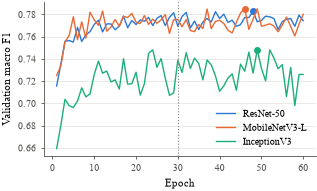

In [17]:
if 'epoch60' in agg:
    paper_style()
    fig, ax = plt.subplots(figsize=(3.5, 2.0))
    for m in MODELS:
        v = agg['epoch60']['curves'][m]['val_f1']
        ax.plot(range(1, len(v) + 1), v, color=MODEL_COLORS[m], lw=1.0, label=MODEL_LABELS[m])
        e60 = agg['epoch60'][m]['best_epoch_60']
        ax.plot(e60, v[e60 - 1], 'o', ms=4, color=MODEL_COLORS[m])
    ax.axvline(30, color='0.5', ls=':', lw=0.8)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Validation macro F1'); ax.legend(fontsize=7)
    plt.show()

## 9. Statistik anotasi per foto — proporsi `good` pada foto full

Foto *full* = foto yang seluruh bijinya dianotasi (termasuk `good`). Proporsi
`good` per foto full menentukan rentang yang dikutip di paper.

In [18]:
photo = pd.read_csv(RUNS_DIR / 'summary' / 'photo_stats.csv')
full = photo[photo.annotation == 'full'].copy()
full['good (%)'] = (100 * full['good'] / full['total']).round(1)
display(full[['photo_id', 'split', 'good', 'total', 'good (%)']])
print(f"Rentang proporsi good di {len(full)} foto full: {full['good (%)'].min():.1f}-{full['good (%)'].max():.1f}%")
display(pd.read_csv(RUNS_DIR / 'summary' / 'photo_stats_summary.csv'))

,photo_id,split,good,total,good (%)
0,IMG_20260814_050353,train,188,341,55.1
2,IMG_20260814_053057,train,234,356,65.7
3,IMG_20260814_053322,train,214,388,55.2
5,IMG_20260814_054039,train,232,369,62.9
18,IMG_20260814_050903,valid,209,340,61.5
19,IMG_20260814_052318,valid,195,333,58.6
24,IMG_20260814_050628,test,216,347,62.2
25,IMG_20260814_052101,test,219,330,66.4


Rentang proporsi good di 8 foto full: 55.1-66.4%


,scope,class,n_photos,min,median,max,sum
0,semua foto,good,30,0,0.0,234,1707
1,semua foto,black,30,0,4.5,81,574
2,semua foto,chipped,30,4,16.0,32,504
3,semua foto,dry_pods,30,6,17.0,35,524
4,semua foto,insect_damage,30,7,15.5,36,538
5,semua foto,total,30,22,54.0,388,3847
6,foto full,good,8,188,215.0,234,1707
7,foto full,black,8,44,61.0,81,496
8,foto full,chipped,8,14,26.0,32,196
9,foto full,dry_pods,8,9,21.5,35,178


## 10. Waktu per sampel 50 g & efisiensi

Satu sampel 50 g = satu foto. Waktu = crop otomatis dari koordinat bbox anotasi
(tanpa deteksi) + klasifikasi seluruh biji di foto itu (GPU, batch 32, setelah
warm-up). Estimasi representatif berasal dari foto *full*. Latensi per citra
(batch 1) diukur ulang 5 kali (mean ± std) dalam sesi yang sama.

In [19]:
for name in ('timing.md', 'support.md'):
    path = SUMMARY_DIR / name
    display(Markdown(path.read_text(encoding='utf-8')) if path.exists() else Markdown(f'_{name} belum ada_'))

| Cakupan | Foto | Biji/foto | Crop (ms) | Model | Total tanpa TTA (ms) | Total D4 (ms) | Forward tanpa TTA (ms) | Forward D4 (ms) | ms/biji tanpa TTA | ms/biji D4 |
|---|--:|--:|--:|---|--:|--:|--:|--:|--:|--:|
| semua foto test | 6 | 144 | 43 | resnet50 | 446 | 2314 | 284 | 2171 | 3.48 | 16.65 |
| semua foto test | 6 | 144 | 43 | mobilenetv3 | 232 | 705 | 94 | 564 | 2.04 | 5.30 |
| semua foto test | 6 | 144 | 43 | inceptionv3 | 579 | 2961 | 391 | 2772 | 4.41 | 21.25 |
| foto full | 2 | 338 | 43 | resnet50 | 990 | 5354 | 666 | 5076 | 2.93 | 15.82 |
| foto full | 2 | 338 | 43 | mobilenetv3 | 482 | 1603 | 213 | 1328 | 1.42 | 4.74 |
| foto full | 2 | 338 | 43 | inceptionv3 | 1307 | 6862 | 921 | 6473 | 3.86 | 20.27 |
| foto defect-only | 4 | 46 | 43 | resnet50 | 174 | 793 | 93 | 719 | 3.76 | 17.06 |
| foto defect-only | 4 | 46 | 43 | mobilenetv3 | 108 | 256 | 35 | 181 | 2.35 | 5.58 |
| foto defect-only | 4 | 46 | 43 | inceptionv3 | 216 | 1010 | 125 | 921 | 4.68 | 21.73 |

Rasio waktu ResNet-50 / MobileNetV3-L (foto full): tanpa TTA: 2.06x dari detik dilaporkan (2.057x dari ms mentah); D4: 3.34x dari detik dilaporkan (3.340x dari ms mentah)


| Model | CI95 F1 (D4) | CI95 F1 (tanpa TTA) | Silhouette seed 42 (5 seed) | Conf benar / salah (seed 42) | I→G tanpa → D4 (seed 42) | I→G tanpa → D4 (5 seed) |
|---|---|---|---|---|---|---|
| resnet50 | 0.784 [0.704, 0.843] | 0.748 [0.655, 0.806] | 0.028 (0.028 ± 0.000) | 0.865 / 0.685 | 28 → 14 / 107 | 28.8 ± 1.8 → 15.4 ± 3.2 |
| mobilenetv3 | 0.747 [0.669, 0.797] | 0.749 [0.635, 0.795] | 0.036 (0.036 ± 0.000) | 0.830 / 0.638 | 22 → 13 / 107 | 24.0 ± 3.1 → 12.8 ± 3.1 |
| inceptionv3 | 0.736 [0.658, 0.798] | 0.715 [0.609, 0.772] | 0.025 (0.025 ± 0.000) | 0.842 / 0.631 | 29 → 23 / 107 | 26.4 ± 2.4 → 20.8 ± 1.9 |

| Model | Parameter total | Trainable | Ukuran (MB) | MAC (G) | Latensi 1 view (ms) | Latensi TTA D4 (ms) |
|---|--:|--:|--:|--:|--:|--:|
| resnet50 | 23,518,277 | 10,245 | 89.7 | 4.09 | 5.994 ± 0.681 | 46.529 ± 0.597 |
| mobilenetv3 | 4,208,437 | 6,405 | 16.1 | 0.22 | 5.958 ± 0.510 | 51.993 ± 9.800 |
| inceptionv3 | 21,795,813 | 10,245 | 83.1 | 5.71 | 11.691 ± 0.449 | 93.809 ± 1.490 |

Latensi: batch 1, cuda, 5 pengukuran x 100 forward (warm-up 10 per pengukuran); mean ± std antar-pengukuran.


## 11. Epoch checkpoint terpilih (semua konfigurasi)

In [20]:
show_section('Epoch checkpoint')

### Epoch checkpoint terpilih (semua konfigurasi)

| Konfigurasi | Model | Epoch per seed (seed: epoch) | Rata-rata |
|---|---|---|--:|
| aug_all_balanced | ResNet-50 | 0: 7, 1: 5, 42: 10 | 7.3 |
| aug_all_balanced | MobileNetV3-L | 0: 10, 1: 12, 42: 9 | 10.3 |
| aug_all_balanced | InceptionV3 | 0: 27, 1: 12, 42: 30 | 23.0 |
| aug_all_x3 | ResNet-50 | 0: 14, 1: 24, 42: 7 | 15.0 |
| aug_all_x3 | MobileNetV3-L | 0: 7, 1: 9, 42: 11 | 9.0 |
| aug_all_x3 | InceptionV3 | 0: 12, 1: 26, 42: 19 | 19.0 |
| bn_frozen | ResNet-50 | 0: 22, 1: 27, 2: 15, 3: 27, 42: 29 | 24.0 |
| bn_frozen | MobileNetV3-L | 0: 13, 1: 21, 2: 28, 3: 30, 42: 12 | 20.8 |
| bn_frozen | InceptionV3 | 0: 27, 1: 22, 2: 20, 3: 13, 42: 24 | 21.2 |
| bnf_aug_all_balanced | ResNet-50 | 0: 27, 1: 30, 42: 11 | 22.7 |
| bnf_aug_all_balanced | MobileNetV3-L | 0: 27, 1: 28, 42: 11 | 22.0 |
| bnf_aug_all_balanced | InceptionV3 | 0: 21, 1: 13, 42: 24 | 19.3 |
| bnf_aug_all_x3 | ResNet-50 | 0: 8, 1: 28, 42: 23 | 19.7 |
| bnf_aug_all_x3 | MobileNetV3-L | 0: 15, 1: 20, 42: 14 | 16.3 |
| bnf_aug_all_x3 | InceptionV3 | 0: 18, 1: 28, 42: 16 | 20.7 |
| bnf_e60 | ResNet-50 | 42: 48 | 48.0 |
| bnf_e60 | MobileNetV3-L | 42: 46 | 46.0 |
| bnf_e60 | InceptionV3 | 42: 49 | 49.0 |
| bnf_focal | ResNet-50 | 0: 20, 1: 26, 42: 17 | 21.0 |
| bnf_focal | MobileNetV3-L | 0: 13, 1: 15, 42: 18 | 15.3 |
| bnf_focal | InceptionV3 | 0: 23, 1: 22, 42: 24 | 23.0 |
| bnf_sampler | ResNet-50 | 0: 25, 1: 28, 42: 28 | 27.0 |
| bnf_sampler | MobileNetV3-L | 0: 24, 1: 20, 42: 8 | 17.3 |
| bnf_sampler | InceptionV3 | 0: 20, 1: 24, 42: 24 | 22.7 |
| focal_loss | ResNet-50 | 0: 4, 1: 30, 42: 6 | 13.3 |
| focal_loss | MobileNetV3-L | 0: 6, 1: 6, 42: 23 | 11.7 |
| focal_loss | InceptionV3 | 0: 28, 1: 30, 42: 12 | 23.3 |
| main | ResNet-50 | 0: 11, 1: 8, 2: 5, 3: 23, 42: 12 | 11.8 |
| main | MobileNetV3-L | 0: 6, 1: 9, 2: 9, 3: 8, 42: 9 | 8.2 |
| main | InceptionV3 | 0: 16, 1: 19, 2: 9, 3: 27, 42: 16 | 17.4 |
| repro_valacc | ResNet-50 | 42: 12 | 12.0 |
| repro_valacc | MobileNetV3-L | 42: 9 | 9.0 |
| repro_valacc | InceptionV3 | 42: 17 | 17.0 |
| weighted_sampler | ResNet-50 | 0: 7, 1: 7, 42: 15 | 9.7 |
| weighted_sampler | MobileNetV3-L | 0: 30, 1: 4, 42: 11 | 15.0 |
| weighted_sampler | InceptionV3 | 0: 19, 1: 18, 42: 21 | 19.3 |


## 12. Pratinjau figur

Dibuat oleh `scripts.revision_figures --main-config bn_frozen` ke
`results/figures/paper_revision_bnfrozen/` (PNG 300 dpi + PDF; figur versi `main`
lama di `results/figures/paper_revision/` tidak ditimpa). Gaya sama dengan
notebook 11 (serif, palet model, lebar 3,5 in), dengan **seluruh teks ≥ 7 pt**.

TTA di figur: d4 | ukuran teks minimum: 7.0 pt


**fig_curves** — `results\figures\paper_revision_bnfrozen\fig_curves.png` (+ `.pdf`)

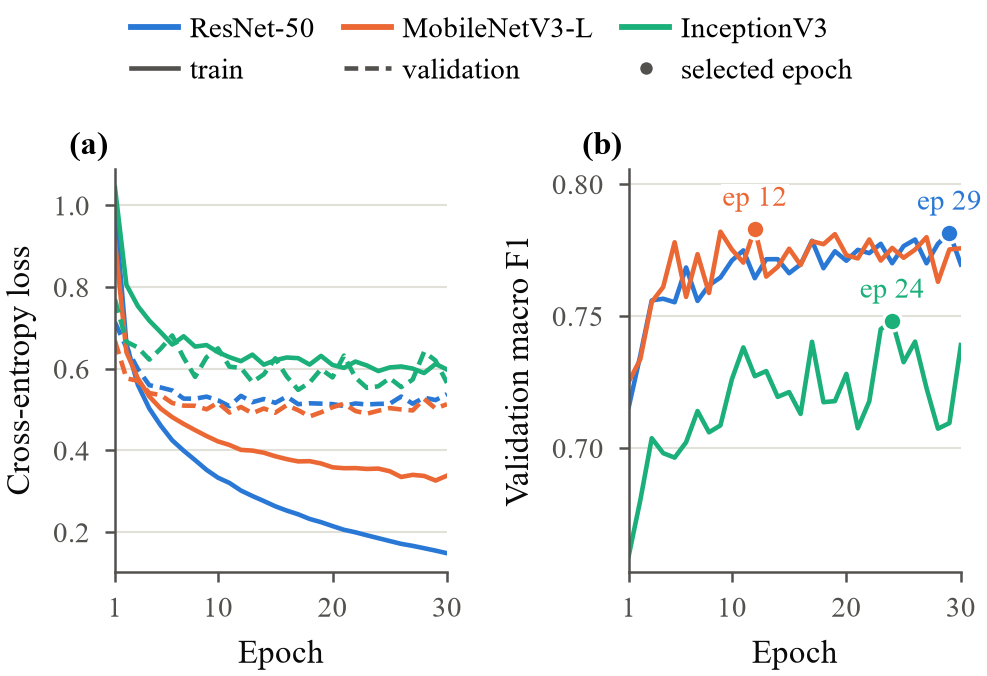

**fig_perclass_f1** — `results\figures\paper_revision_bnfrozen\fig_perclass_f1.png` (+ `.pdf`)

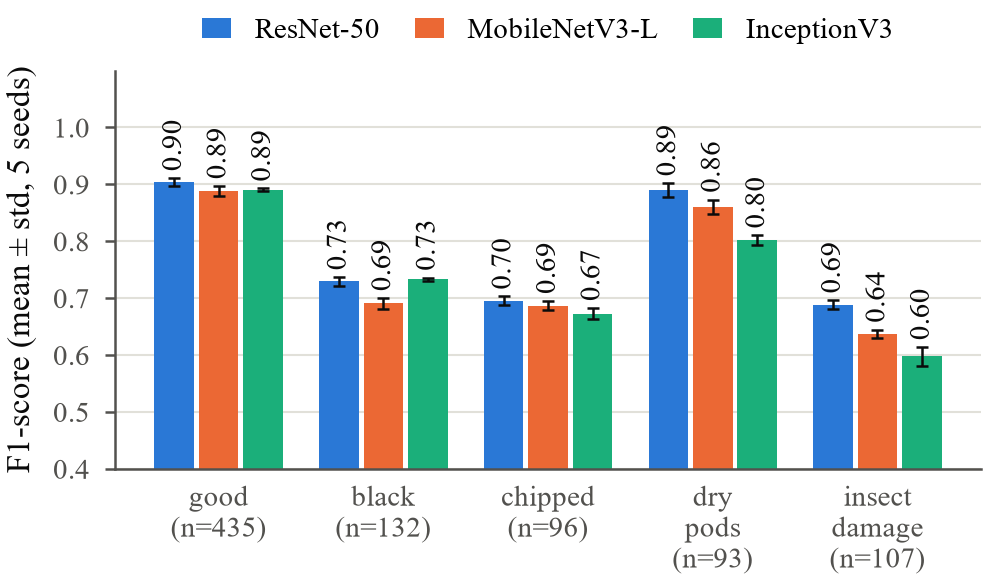

**fig_confusion** — `results\figures\paper_revision_bnfrozen\fig_confusion.png` (+ `.pdf`)

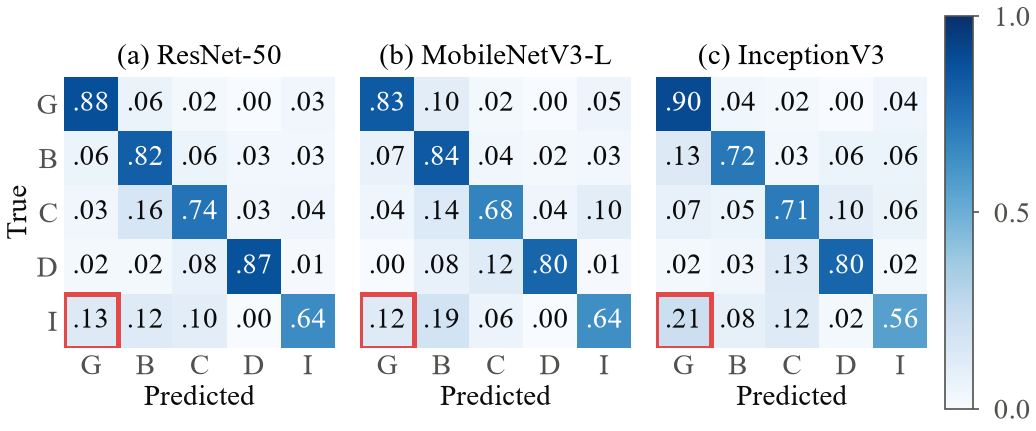

**fig_tta** — `results\figures\paper_revision_bnfrozen\fig_tta.png` (+ `.pdf`)

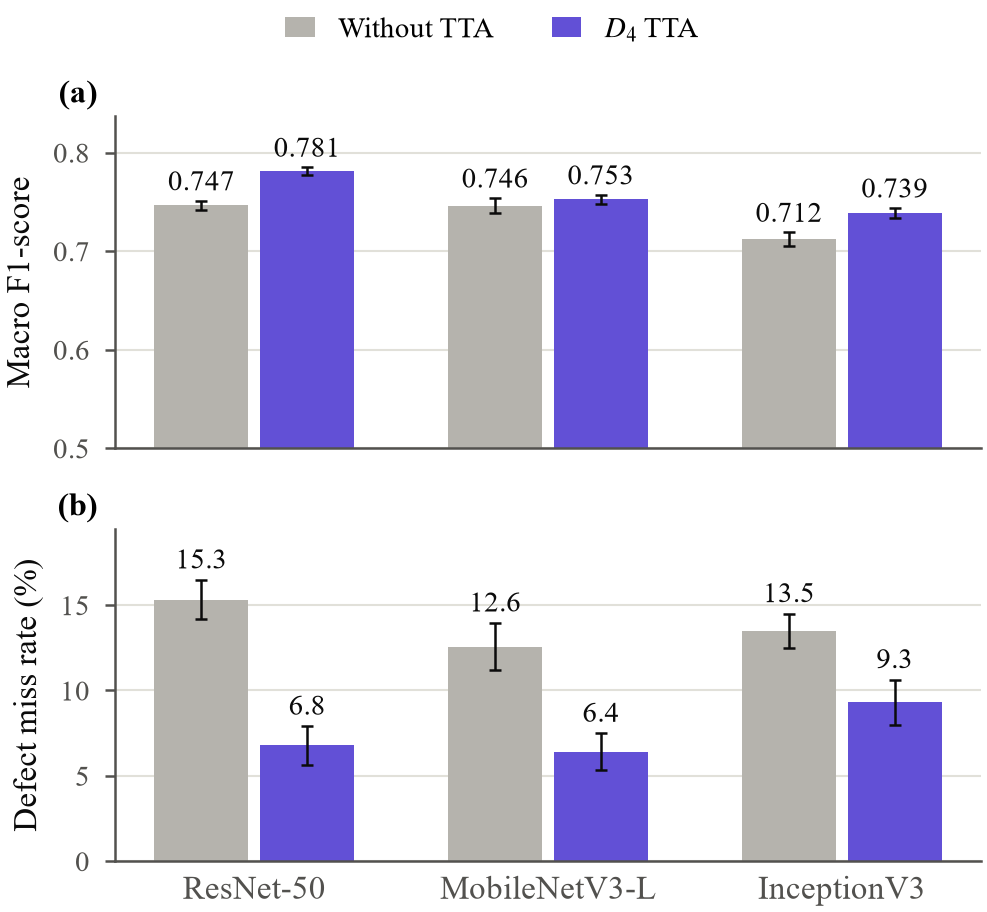

**fig_tradeoff** — `results\figures\paper_revision_bnfrozen\fig_tradeoff.png` (+ `.pdf`)

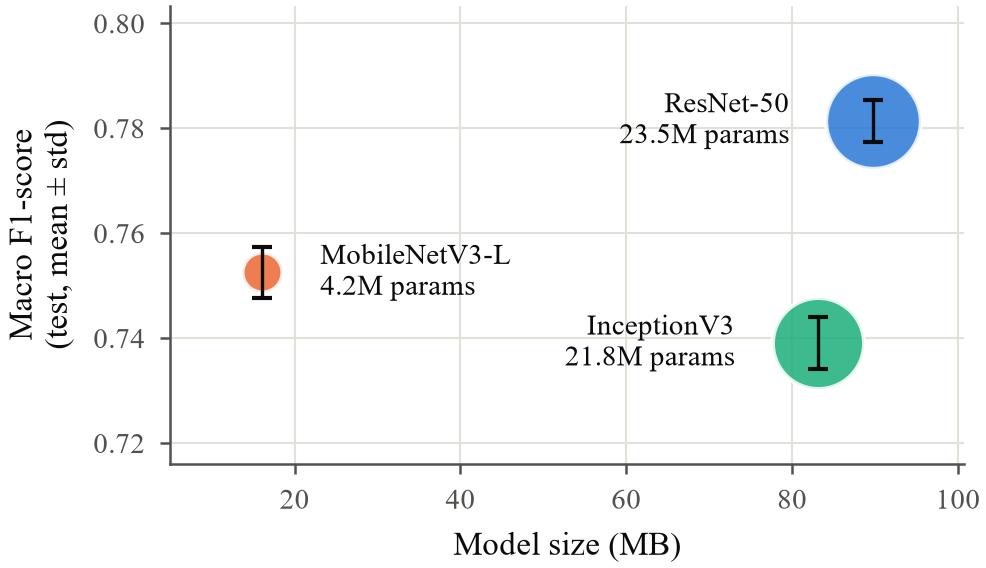

**fig_gradcam** — `results\figures\paper_revision_bnfrozen\fig_gradcam.png` (+ `.pdf`)

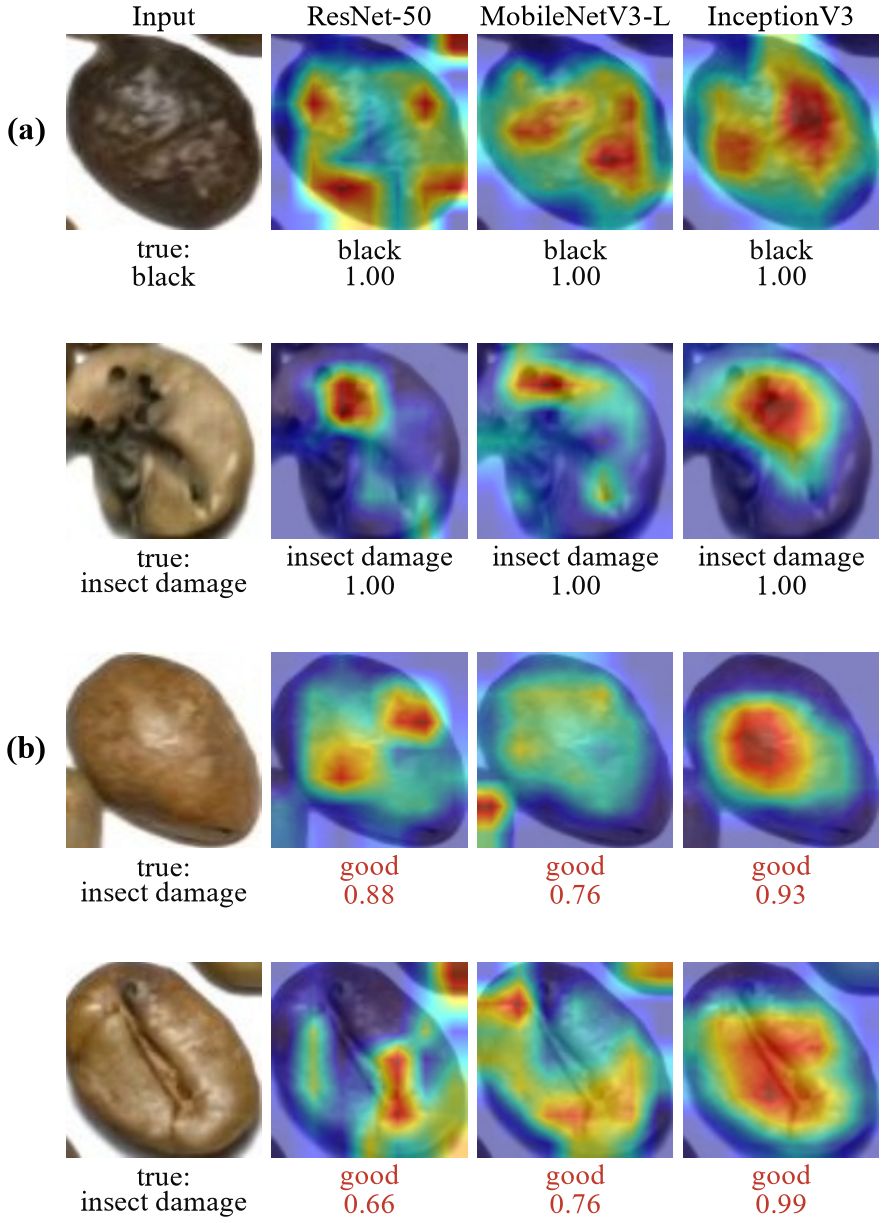

**fig_confidence** — `results\figures\paper_revision_bnfrozen\fig_confidence.png` (+ `.pdf`)

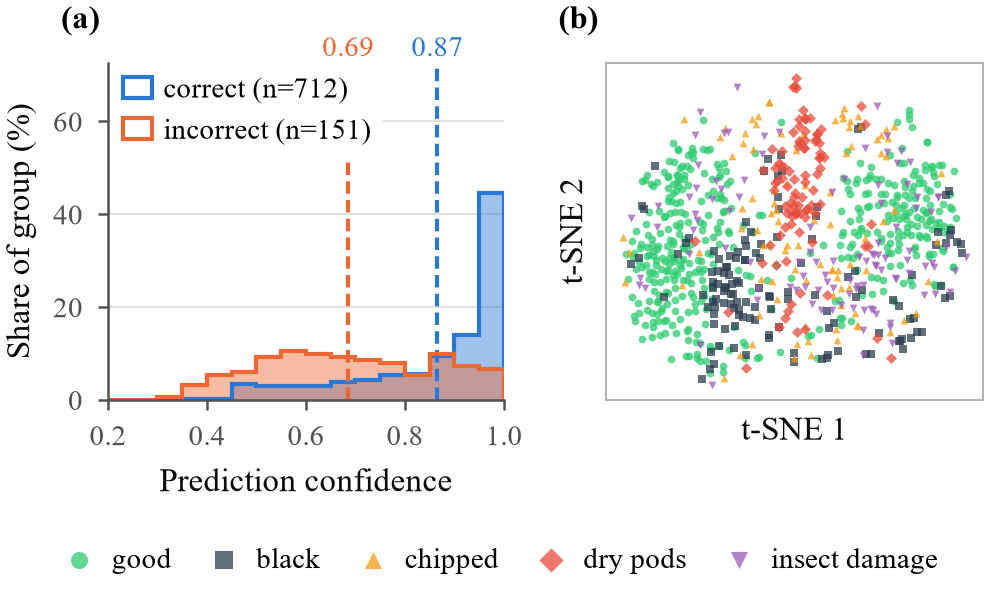

**fig_bn_effect** — `results\figures\paper_revision_bnfrozen\fig_bn_effect.png` (+ `.pdf`)

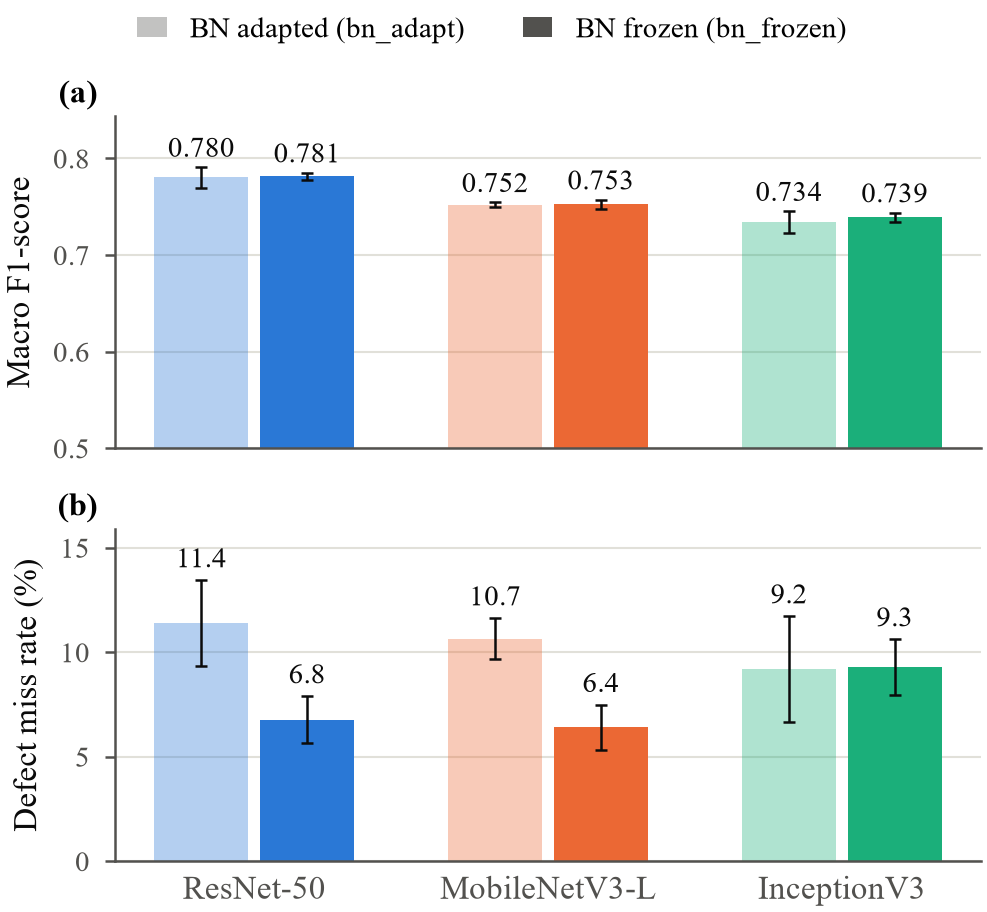

In [21]:
FIGURES = ['fig_curves', 'fig_perclass_f1', 'fig_confusion', 'fig_tta',
           'fig_tradeoff', 'fig_gradcam', 'fig_confidence', 'fig_bn_effect']
fig_meta = results.get('figures_bnfrozen' if MAIN_CONFIG == 'bn_frozen' else 'figures', {})
print('TTA di figur:', fig_meta.get('tta'), '| ukuran teks minimum:', fig_meta.get('min_font_pt'), 'pt')
for name in FIGURES:
    png = FIG_DIR / f'{name}.png'
    if not png.exists():
        continue
    display(Markdown(f'**{name}** — `{png.relative_to(PROJECT_ROOT)}` (+ `.pdf`)'))
    display(Image(filename=str(png), width=560))

In [22]:
# Aturan pemilihan sampel Grad-CAM dan ringkasan figur confidence.
{k: fig_meta.get(k) for k in ('fig_gradcam', 'fig_confidence')}

{'fig_gradcam': {'tta': 'd4',
  'row_a': ['IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_053.jpg',
   'IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_047.jpg'],
  'row_b': ['IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_262.jpg',
   'IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_306.jpg'],
  'rule_a': 'black & insect_damage benar di 3 model, confidence minimum antar-model tertinggi',
  'rule_b': 'insect_damage -> good di ketiga model, rata-rata P(good) tertinggi',
  'n_insect_good_all3': 5,
  'n_insect_good_ge2': 17,
  'row_b_n_models_good': [3, 3],
  'labels': {'IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_053.jpg': {'resnet50': ['black',
     0.9998996433333595],
    'mobilenetv3': ['black', 0.9993249940625496],
    'inceptionv3': ['black', 0.9963024313088741]},
   'IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_047.jpg': {'resnet50': ['insect_damage',
     0.9993140698072